# Workforce & Recruiting — exploratory analysis

**Synthetic educational data.** The uploaded employee sample is treated as teaching data; original provenance remains unconfirmed. Monthly history, locations, exit reasons and all recruiting records are simulated with seed 42. Original-sample comparisons below are separate from simulated monthly KPIs. No causation or real business impact is claimed.

This notebook profiles inputs, checks assumptions, explores distributions and attrition associations, then reconciles the simulated pipeline outputs. Each code cell has been executed; printed results and charts come from those executions.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'data/raw').exists() else Path.cwd().parent
assert (ROOT / 'data/raw/source/HR-Employee-Attrition.csv').exists(), 'Run from project root or notebooks/'
employees = pd.read_csv(ROOT / 'data/raw/source/HR-Employee-Attrition.csv')
print('Rows, columns:', employees.shape)
print(employees.head(5).to_string(index=False))


## 1. Schema and missing values
Integer-coded ratings are ordinal categories. EmployeeNumber is an identifier, not a quantitative predictor. Missing dates are absent fields, not null cells that can be filled.

In [2]:
profile = pd.DataFrame({'dtype': employees.dtypes.astype(str), 'nulls': employees.isna().sum(), 'distinct': employees.nunique()})
print(profile.to_string())
print('Date-named columns:', [c for c in employees if 'date' in c.lower()])


                           dtype  nulls  distinct
Age                        int64      0        43
Attrition                 object      0         2
BusinessTravel            object      0         3
DailyRate                  int64      0       886
Department                object      0         3
DistanceFromHome           int64      0        29
Education                  int64      0         5
EducationField            object      0         6
EmployeeCount              int64      0         1
EmployeeNumber             int64      0      1470
EnvironmentSatisfaction    int64      0         4
Gender                    object      0         2
HourlyRate                 int64      0        71
JobInvolvement             int64      0         4
JobLevel                   int64      0         5
JobRole                   object      0         9
JobSatisfaction            int64      0         4
MaritalStatus             object      0         3
MonthlyIncome              int64      0      1349


## 2. Duplicate keys, blank strings and constant fields
Do not silently drop conflicting employee records. The pipeline rejects duplicate employee-month keys and duplicate application IDs.

In [3]:
text = employees.select_dtypes('object')
print('Duplicate rows:', employees.duplicated().sum())
print('Duplicate employee IDs:', employees.EmployeeNumber.duplicated().sum())
print('Blank text cells:', text.apply(lambda s: s.str.strip().eq('').sum()).sum())
print('Constant fields:', [c for c in employees if employees[c].nunique() == 1])
print('Whitespace differences:', text.apply(lambda s: s.ne(s.str.strip()).sum()).to_dict())


Duplicate rows: 0
Duplicate employee IDs: 0
Blank text cells: 0
Constant fields: ['EmployeeCount', 'Over18', 'StandardHours']
Whitespace differences: {'Attrition': 0, 'BusinessTravel': 0, 'Department': 0, 'EducationField': 0, 'Gender': 0, 'JobRole': 0, 'MaritalStatus': 0, 'Over18': 0, 'OverTime': 0}


## 3. Categories and coded scales
Inspect exact labels before mapping them. A different recruitment or department label must not be assumed equivalent without a documented mapping.

In [4]:
for col in ['Attrition', 'Department', 'JobRole', 'OverTime', 'BusinessTravel', 'JobSatisfaction', 'JobLevel']:
    print('\n' + col)
    print(employees[col].value_counts(dropna=False).to_string())



Attrition
Attrition
No     1233
Yes     237

Department
Department
Research & Development    961
Sales                     446
Human Resources            63

JobRole
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52

OverTime
OverTime
No     1054
Yes     416

BusinessTravel
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150

JobSatisfaction
JobSatisfaction
4    459
3    442
1    289
2    280

JobLevel
JobLevel
1    543
2    534
3    218
4    106
5     69


## 4. Numeric ranges and logical consistency
Unusual values are not automatically incorrect. Company tenure must not exceed total experience; role, manager and promotion tenure must not exceed company tenure.

In [5]:
cols = ['Age','MonthlyIncome','YearsAtCompany','TotalWorkingYears','DistanceFromHome']
print(employees[cols].describe().round(2).to_string())
for left, right in [('YearsAtCompany','TotalWorkingYears'), ('YearsInCurrentRole','YearsAtCompany'), ('YearsWithCurrManager','YearsAtCompany'), ('YearsSinceLastPromotion','YearsAtCompany')]:
    print(left, '>', right, ':', int((employees[left] > employees[right]).sum()))


           Age  MonthlyIncome  YearsAtCompany  TotalWorkingYears  DistanceFromHome
count  1470.00        1470.00         1470.00            1470.00           1470.00
mean     36.92        6502.93            7.01              11.28              9.19
std       9.14        4707.96            6.13               7.78              8.11
min      18.00        1009.00            0.00               0.00              1.00
25%      30.00        2911.00            3.00               6.00              2.00
50%      36.00        4919.00            5.00              10.00              7.00
75%      43.00        8379.00            9.00              15.00             14.00
max      60.00       19999.00           40.00              40.00             29.00
YearsAtCompany > TotalWorkingYears : 0
YearsInCurrentRole > YearsAtCompany : 0
YearsWithCurrManager > YearsAtCompany : 0
YearsSinceLastPromotion > YearsAtCompany : 0


## 5. Outlier flags
Tukey fences use Q1 − 1.5×IQR and Q3 + 1.5×IQR. Flagged values are retained because no evidence establishes that they are data errors. Currency is unspecified.

In [6]:
flags=[]
for col in ['Age','MonthlyIncome','YearsAtCompany','TotalWorkingYears','YearsSinceLastPromotion']:
    q1,q3=employees[col].quantile([.25,.75]);iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    flags.append({'field':col,'lower':lower,'upper':upper,'flagged':int(((employees[col]<lower)|(employees[col]>upper)).sum())})
print(pd.DataFrame(flags).to_string(index=False))


                  field   lower   upper  flagged
                    Age    10.5    62.5        0
          MonthlyIncome -5291.0 16581.0      114
         YearsAtCompany    -6.0    18.0      104
      TotalWorkingYears    -7.5    28.5       63
YearsSinceLastPromotion    -4.5     7.5      107


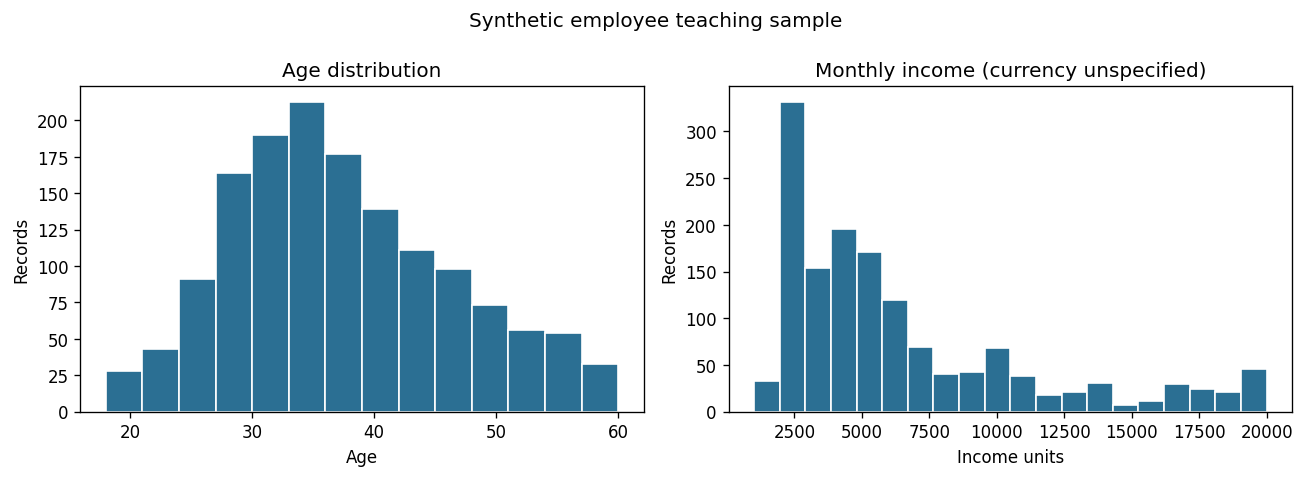

In [7]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(employees.Age,bins=14,color='#2B6F93',edgecolor='white'); axes[0].set(title='Age distribution',xlabel='Age',ylabel='Records')
axes[1].hist(employees.MonthlyIncome,bins=20,color='#2B6F93',edgecolor='white'); axes[1].set(title='Monthly income (currency unspecified)',xlabel='Income units',ylabel='Records')
fig.suptitle('Synthetic employee teaching sample');fig.tight_layout()


## 6. Attrition share — not a monthly rate
The original file has no observation dates. Use one row per employee and call this an attrition-label share, never an annual or monthly attrition rate.

In [8]:
employees['exit_flag'] = employees.Attrition.eq('Yes').astype(int)
employees['tenure_band'] = pd.cut(employees.YearsAtCompany,[-np.inf,1,3,5,10,np.inf],right=False,labels=['<1 year','1–<3 years','3–<5 years','5–<10 years','10+ years'])
print('Attrition Yes:', employees.exit_flag.sum())
print('Records:', len(employees))
print('Dataset attrition share:', f'{employees.exit_flag.mean():.2%}')


Attrition Yes: 237
Records: 1470
Dataset attrition share: 16.12%


## 7. Three descriptive pattern comparisons
Compare overtime, tenure and department. Always show denominators. These are descriptive comparisons, not formal significance tests or causal effects.

In [9]:
patterns=[]
for field in ['OverTime','tenure_band','Department']:
    table=employees.groupby(field,observed=True).exit_flag.agg(['size','sum','mean'])
    table.columns=['records','attrition_yes','attrition_share']
    print('\n'+field);print(table.to_string())
    patterns.append(table)



OverTime
          records  attrition_yes  attrition_share
OverTime                                         
No           1054            110         0.104364
Yes           416            127         0.305288

tenure_band
             records  attrition_yes  attrition_share
tenure_band                                         
<1 year           44             16         0.363636
1–<3 years       298             86         0.288591
3–<5 years       238             39         0.163866
5–<10 years      524             58         0.110687
10+ years        366             38         0.103825

Department
                        records  attrition_yes  attrition_share
Department                                                     
Human Resources              63             12         0.190476
Research & Development      961            133         0.138398
Sales                       446             92         0.206278


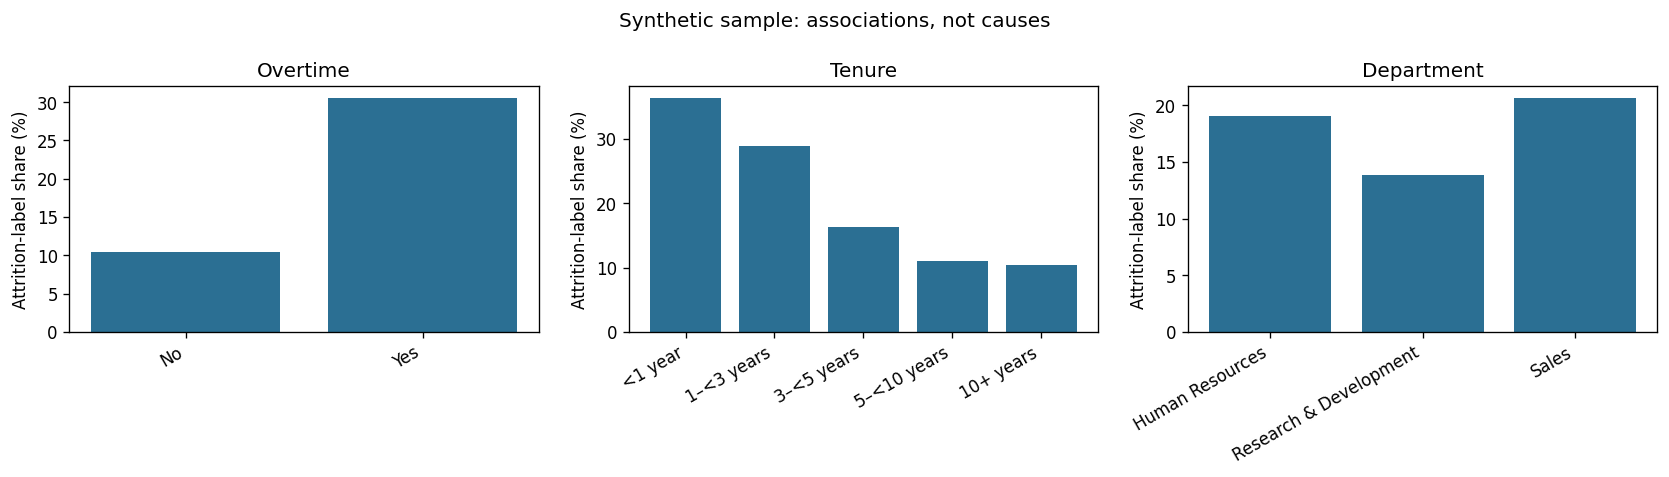

In [10]:
fig, axes=plt.subplots(1,3,figsize=(14,4))
for ax,field,table in zip(axes,['Overtime','Tenure','Department'],patterns):
    ax.bar(range(len(table)),table.attrition_share*100,color='#2B6F93')
    ax.set_xticks(range(len(table)),table.index.astype(str),rotation=30,ha='right')
    ax.set(title=field,ylabel='Attrition-label share (%)')
fig.suptitle('Synthetic sample: associations, not causes');fig.tight_layout()


## 8. Department × overtime: volume versus rate
Prioritize workload investigation using the number of labelled exits within overtime groups, while also showing rates. This avoids ranking a small department solely by its percentage.

In [11]:
cross = employees.groupby(['Department','OverTime']).exit_flag.agg(['size','sum','mean'])
cross.columns=['records','attrition_yes','attrition_share']
print(cross.to_string())
overtime = cross.xs('Yes',level='OverTime').sort_values('attrition_yes',ascending=False)
print('Highest overtime-group exit-label count:', overtime.index[0])


                                 records  attrition_yes  attrition_share
Department             OverTime                                         
Human Resources        No             46              7         0.152174
                       Yes            17              5         0.294118
Research & Development No            690             59         0.085507
                       Yes           271             74         0.273063
Sales                  No            318             44         0.138365
                       Yes           128             48         0.375000
Highest overtime-group exit-label count: Research & Development


## 9. Simulated monthly files and their grain
Employee-month records repeat people across months. Recruiting records are independent application cohorts with no employee crosswalk. Do not join raw facts on department.

In [12]:
master=pd.read_csv(ROOT/'data/output/master_employees.csv')
recruiting=pd.read_csv(ROOT/'data/output/recruiting_funnel.csv')
kpis=pd.read_csv(ROOT/'data/output/kpi_monthly.csv')
interim=pd.read_csv(ROOT/'data/interim/employee_months_derived.csv')
print('Unique employee master:',len(master))
print('Employee-month rows:',len(interim))
print('Applications:',len(recruiting))
print('Monthly department/site groups:',len(kpis))
assert master.employee_id.is_unique
assert recruiting.application_id.is_unique
assert not interim.duplicated(['employee_id','report_month']).any()
assert not kpis.duplicated(['report_month','Department','location']).any()


Unique employee master: 1470
Employee-month rows: 16131
Applications: 2400
Monthly department/site groups: 108


## 10. Monthly reconciliation and denominators
Average headcount is (opening + closing)/2. Same-month hires and exits are retained. Monthly stock counts cannot be summed to obtain annual headcount.

In [13]:
total=pd.read_csv(ROOT/'data/output/monthly_totals.csv')
assert (total.opening+total.hires-total.exits==total.closing).all()
assert (total.voluntary+total.involuntary==total.exits).all()
assert np.allclose(total.attrition_rate,total.exits/((total.opening+total.closing)/2))
print(total[['report_month','opening','hires','exits','closing','attrition_rate']].to_string(index=False))


report_month  opening  hires  exits  closing  attrition_rate
     2025-01     1436      3     21     1418        0.014716
     2025-02     1418      4     24     1398        0.017045
     2025-03     1398      3     22     1379        0.015844
     2025-04     1379      4     22     1361        0.016058
     2025-05     1361      2     15     1348        0.011074
     2025-06     1348      4     21     1331        0.015677
     2025-07     1331      2     19     1314        0.014367
     2025-08     1314      7     18     1303        0.013756
     2025-09     1303      1     20     1284        0.015462
     2025-10     1284      3     14     1273        0.010950
     2025-11     1273      1     22     1252        0.017426
     2025-12     1252      0     19     1233        0.015292


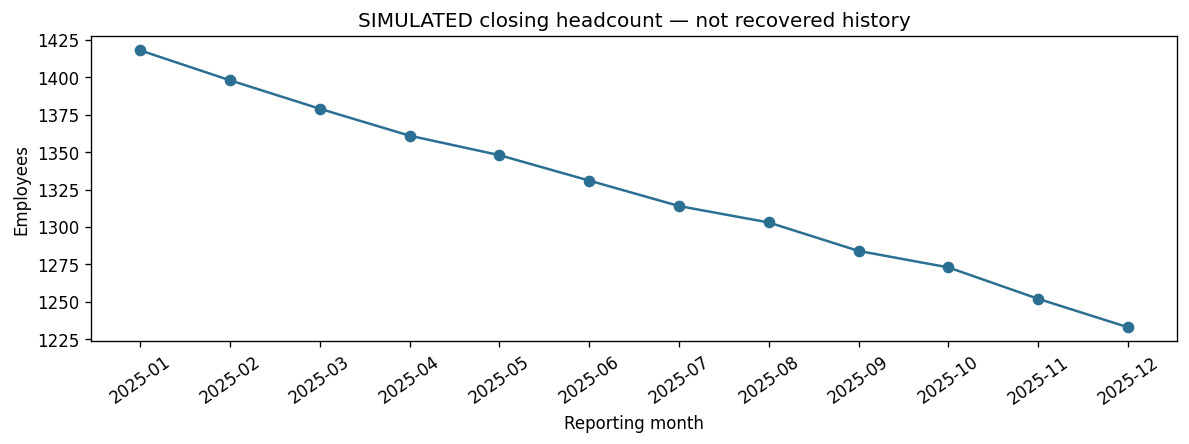

In [14]:
fig,ax=plt.subplots(figsize=(10,3.8))
ax.plot(total.report_month,total.closing,marker='o',color='#2B6F93')
ax.set(title='SIMULATED closing headcount — not recovered history',ylabel='Employees',xlabel='Reporting month')
ax.tick_params(axis='x',rotation=35);fig.tight_layout()


## 11. Recruiting timing and cohort caveats
Time to hire ends at acceptance. Offer acceptance excludes pending offers. Recent application cohorts have less follow-up time. These recruiting results are generated and do not explain employee hires.

In [15]:
print(recruiting.offer_decision.value_counts().to_string())
print(total[['report_month','applications','accepted','declined','pending','time_to_hire_days','offer_acceptance_rate','funnel_conversion']].round(4).to_string(index=False))
print('Count of recorded applications:', total.applications.sum())
assert total.applications.sum()==len(recruiting)


offer_decision
Not offered    1874
Accepted        403
Declined        113
Pending          10
report_month  applications  accepted  declined  pending  time_to_hire_days  offer_acceptance_rate  funnel_conversion
     2025-01           186         3         1        9            23.3333                 0.7500             0.0699
     2025-02           168        26         3        5            27.0769                 0.8966             0.0357
     2025-03           210        37         8       16            25.2162                 0.8222             0.1143
     2025-04           186        37        11        8            24.1622                 0.7708             0.0699
     2025-05           223        27        13       12            24.0000                 0.6750             0.1076
     2025-06           195        36        10        9            27.1111                 0.7826             0.0769
     2025-07           214        33        13       10            26.4545            

## 12. SQL versus Python reconciliation
The SQL query separately aggregates employee flags and recruiting dates, then computes the same weighted ratios. It does not read Python KPI output as its source.

In [16]:
sql=pd.read_csv(ROOT/'data/output/kpi_monthly_sql.csv')
keys=['report_month','Department','location']
numeric=[c for c in kpis if c not in keys]
a=kpis.sort_values(keys).reset_index(drop=True)
b=sql.sort_values(keys).reset_index(drop=True)
assert a[keys].equals(b[keys])
assert np.allclose(a[numeric].to_numpy(float),b[numeric].to_numpy(float),equal_nan=True,atol=1e-9)
print('SQL/Python group keys and all numerical output columns match.')


SQL/Python group keys and all numerical output columns match.


## Conclusion and next action
Investigate overtime workload in the department with the largest overtime-group exit-label count, supported by the cross-tab above. Validate using real dated records and exit interviews before a workload-management pilot. Tenure patterns suggest onboarding is another hypothesis. The teaching sample is synthetic, the monthly history is invented, and correlations do not establish causation. Read docs/insights.md for the evidence and recommendation.